In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [56]:
train = pd.read_csv("../raw_data/train.csv", keep_default_na=False, na_values=["NA"])
test = pd.read_csv("../raw_data/test.csv", keep_default_na=False, na_values=["NA"])

In [57]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [58]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [59]:
na = train.isna().sum()
na_sort = na[na > 0].sort_values(ascending=False)
na_precent = (na_sort / len(train) * 100).round(2)
pd.DataFrame({"missing": na_sort, "percent": na_precent})

,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55


In [33]:
na_test = test.isna().sum()
na_sort_test = na_test[na_test > 0].sort_values(ascending=False)
na_precent_test = (na_sort_test / len(test) * 100).round(2)
pd.DataFrame({"missing": na_sort_test, "percent": na_precent_test})

,missing,percent
PoolQC,1456,99.79
MiscFeature,1408,96.50
Alley,1352,92.67
Fence,1169,80.12
MasVnrType,894,61.27
FireplaceQu,730,50.03
LotFrontage,227,15.56
GarageCond,78,5.35
GarageYrBlt,78,5.35
GarageQual,78,5.35


Посмотрел описания колонок с пропусками, большинство из них это просто категория домов, у которых нет той или иной части дома, вот эти столбцы: PoolQC, MiscFeature, Alley, Fence, FireplaceQu, GarageType, GarageYrBlt, GarageFinish, GarageQual, GarageCond, BsmtFinType2, BsmtExposure, BsmtFinType1, BsmtCond, BsmtQual


Столбцы, в которых нужно заполнить реальные пропуски в трейне: LotFrontage, MasVnrArea, Electrical, MasVnrType
Столбцы, в которых нужно заполнить реальные пропуски в тесте, помимо тех, что и в трейне: MSZoning, BsmtFullBath, BsmtHalfBath, Functional, Utilities, GarageCars, GarageArea, TotalBsmtSF, KitchenQual, BsmtUnfSF, BsmtFinSF2, BsmtFinSF1, Exterior2nd, Exterior1st, SaleType

GarageType в тестовой выборке имеет чуть меньше пропусков, среди признаков гаража, странно, надо будет понять как так может быть

у признаков подвала тоже есть несоответствие и в трейне и в тесте

Exterior2nd имеет один пропуск в тесте, но он должен быть, только если он реально есть, решил ставить "Unknown" (см. план ниже)

In [ ]:
# Заменяем пропуски:

# Категориальные признаки: 
# PoolQC -> "None"
# MiscFeature -> "None" 
# Alley -> "None"
# Fence -> "None"
# FireplaceQu -> "None"
# GarageType -> "None"
# GarageFinish -> "None"
# GarageQual -> "None"
# GarageCond -> "None"
# BsmtExposure -> "None"
# BsmtFinType2 -> "None"
# BsmtFinType1 -> "None"
# BsmtCond -> "None"
# BsmtQual -> "None"
# MasVnrType -> mode
# Electrical -> mode
# MSZoning -> mode
# Utilities -> mode
# Functional -> mode
# KitchenQual -> mode
# SaleType -> "Unknown"
# Exterior1st -> mode
# Exterior2nd -> "Unknown"

# Числовые признаки:
# GarageYrBlt -> 0
# MasVnrArea -> median
# LotFrontage -> median 
# BsmtFinSF1 -> median
# BsmtFinSF2 -> median
# BsmtUnfSF -> median
# TotalBsmtSF -> median 
# BsmtFullBath -> mode (как категориальный)
# BsmtHalfBath -> mode (как категориальный)
# GarageCars -> mode (как категориальный)
# GarageArea -> median

# так же есть реальные пропуски в признаках подвала и гаража, то есть заполняем None, только там, где у других фичей этой части дома тоже пропуски
# для таких случаев в числовых признаках будет ставиться 0, а не среднее или медиана, важно следить за фичами с одинаковым префиксом
# если Exterior1st и Exterior2nd пустые в одном и том же доме, у обоих ставим "Unknown"
# в фичах с префиксом MasVnr, Garage и Bsmt заполняем с учетом других фич с этим же префиксом, смысл не должен расходиться 

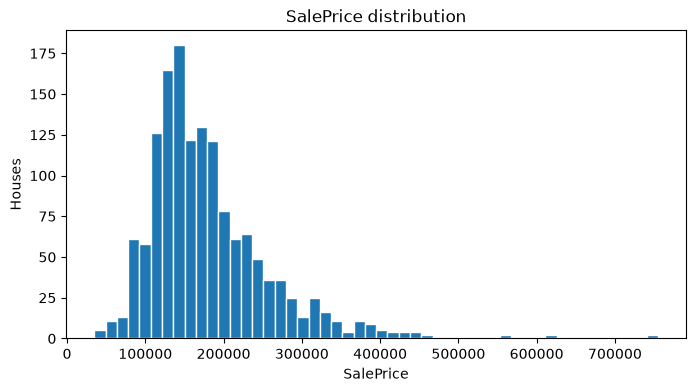

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train["SalePrice"], bins=50, edgecolor="white")
ax.set(title="SalePrice distribution", xlabel="SalePrice", ylabel="Houses")
plt.show()


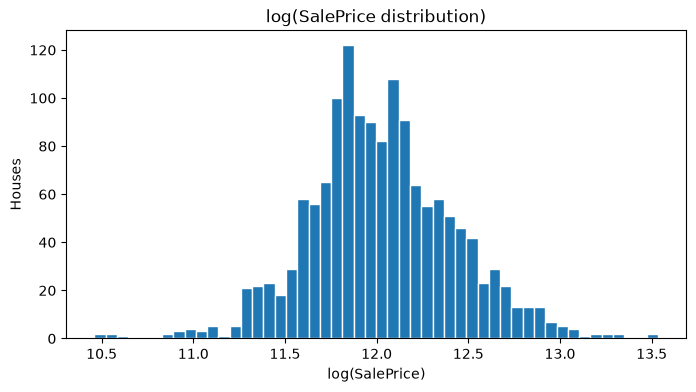

In [78]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log(train["SalePrice"]), bins=50, edgecolor="white")
ax.set(title="log(SalePrice) distribution", xlabel="log(SalePrice)", ylabel="Houses")
plt.show()

Таргет был скошен вправо, поэтому его будем логарифмировать. Помимо этого оценка на каггле тоже будет в логарифмах, так ошибка для разных цен будет одинакова в процентах.

In [ ]:
train["LogPrice"] = np.log(train["SalePrice"])

In [79]:
num_cols = train.select_dtypes("number").columns.drop(["Id", "SalePrice", "LogPrice"])
cat_cols = train.select_dtypes(exclude="number").columns

In [90]:
num_cols.value_counts().sum()

np.int64(36)

In [89]:
cat_cols.value_counts().sum()

np.int64(43)

In [99]:
corr = train[num_cols].corrwith(train["LogPrice"]).sort_values(ascending=False)
corr.head(20)

OverallQual     0.817184
GrLivArea       0.700927
GarageCars      0.680625
GarageArea      0.650888
TotalBsmtSF     0.612134
1stFlrSF        0.596981
FullBath        0.594771
YearBuilt       0.586570
YearRemodAdd    0.565608
GarageYrBlt     0.541073
TotRmsAbvGrd    0.534422
Fireplaces      0.489449
MasVnrArea      0.430809
BsmtFinSF1      0.372023
LotFrontage     0.355878
WoodDeckSF      0.334135
OpenPorchSF     0.321053
2ndFlrSF        0.319300
HalfBath        0.313982
LotArea         0.257320
dtype: float64

In [100]:
corr.tail()

YrSold          -0.037263
LowQualFinSF    -0.037963
MSSubClass      -0.073959
KitchenAbvGr    -0.147548
EnclosedPorch   -0.149050
dtype: float64

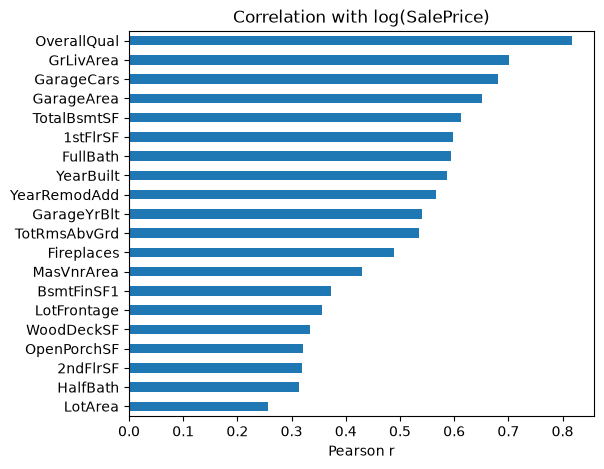

In [101]:
top = corr.abs().sort_values(ascending=False).head(20).index
fig, ax = plt.subplots(figsize=(6, 5))
corr[top][::-1].plot.barh(ax=ax)
ax.set(title="Correlation with log(SalePrice)", xlabel="Pearson r")
plt.show()

In [102]:
corr = train[num_cols].corrwith(train["LogPrice"], method="spearman").sort_values(ascending=False)
corr.head(20)

OverallQual     0.809829
GrLivArea       0.731310
GarageCars      0.690711
YearBuilt       0.652682
GarageArea      0.649379
FullBath        0.635957
TotalBsmtSF     0.602725
GarageYrBlt     0.593788
1stFlrSF        0.575408
YearRemodAdd    0.571159
TotRmsAbvGrd    0.532586
Fireplaces      0.519247
OpenPorchSF     0.477561
LotArea         0.456461
MasVnrArea      0.421309
LotFrontage     0.409076
WoodDeckSF      0.353802
HalfBath        0.343008
BsmtFinSF1      0.301871
2ndFlrSF        0.293598
dtype: float64

In [103]:
corr.tail()

MiscVal         -0.062727
LowQualFinSF    -0.067719
OverallCond     -0.129325
KitchenAbvGr    -0.164826
EnclosedPorch   -0.218394
dtype: float64

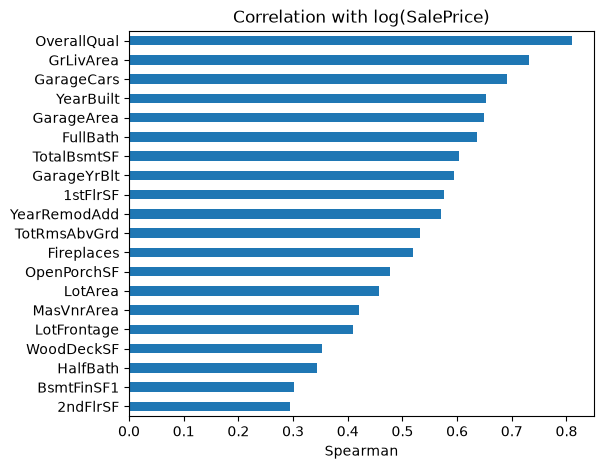

In [96]:
top = corr.abs().sort_values(ascending=False).head(20).index
fig, ax = plt.subplots(figsize=(6, 5))
corr[top][::-1].plot.barh(ax=ax)
ax.set(title="Correlation with log(SalePrice)", xlabel="Spearman")
plt.show()

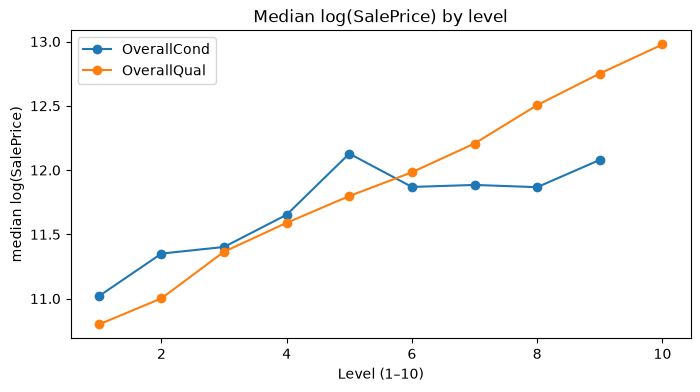

In [106]:
med_cond = train.groupby("OverallCond")["LogPrice"].median()
med_qual = train.groupby("OverallQual")["LogPrice"].median()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(med_cond.index, med_cond.values, marker="o", label="OverallCond")
ax.plot(med_qual.index, med_qual.values, marker="o", label="OverallQual")
ax.set(title="Median log(SalePrice) by level", xlabel="Level (1–10)", ylabel="median log(SalePrice)")
ax.legend()
plt.show()

In [107]:
train.groupby("OverallCond")[["YearBuilt", "SalePrice"]].median()

,YearBuilt,SalePrice
OverallCond,,
1,1922.0,61000.0
2,1920.0,85000.0
3,1952.0,89500.0
4,1950.0,115000.0
5,1998.0,185000.0
6,1960.5,142750.0
7,1954.0,145000.0
8,1945.5,142500.0
9,1938.0,176200.0


Тут видим, что новые дома чаще получаеют оценку 5 по 'OverallCond', но также и получаеют более высокую цену. А оценки 6-9 получают тоже старые дома, возможно после ремонта или просто они более статусные, чем новые. То есть сама корреляция не дает нам всей необходимой информации, так как тут еще влияет признак как минимум года постройки.

In [116]:
corr_matrix = train[num_cols].corr()

mask = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
upper = corr_matrix.where(mask)

pairs = upper.stack()
pairs[pairs.abs() > 0.8].sort_values(ascending=False)

GarageCars   GarageArea      0.882475
YearBuilt    GarageYrBlt     0.825667
GrLivArea    TotRmsAbvGrd    0.825489
TotalBsmtSF  1stFlrSF        0.819530
dtype: float64

Тут я решил, что будем убирать GarageArea, GarageYrBlt, TotRmsAbvGrd и 1stFlrSF, так как они имеют схожие признаки с корреляцией между собой > 0.8, плюс избежим некоторые заполнения пропусков. Для деревьев по сути хуже мы не сделаем, а вот для линейных моделей это поможет стабилизировать веса. И тут все еще проверям числовые фичи.

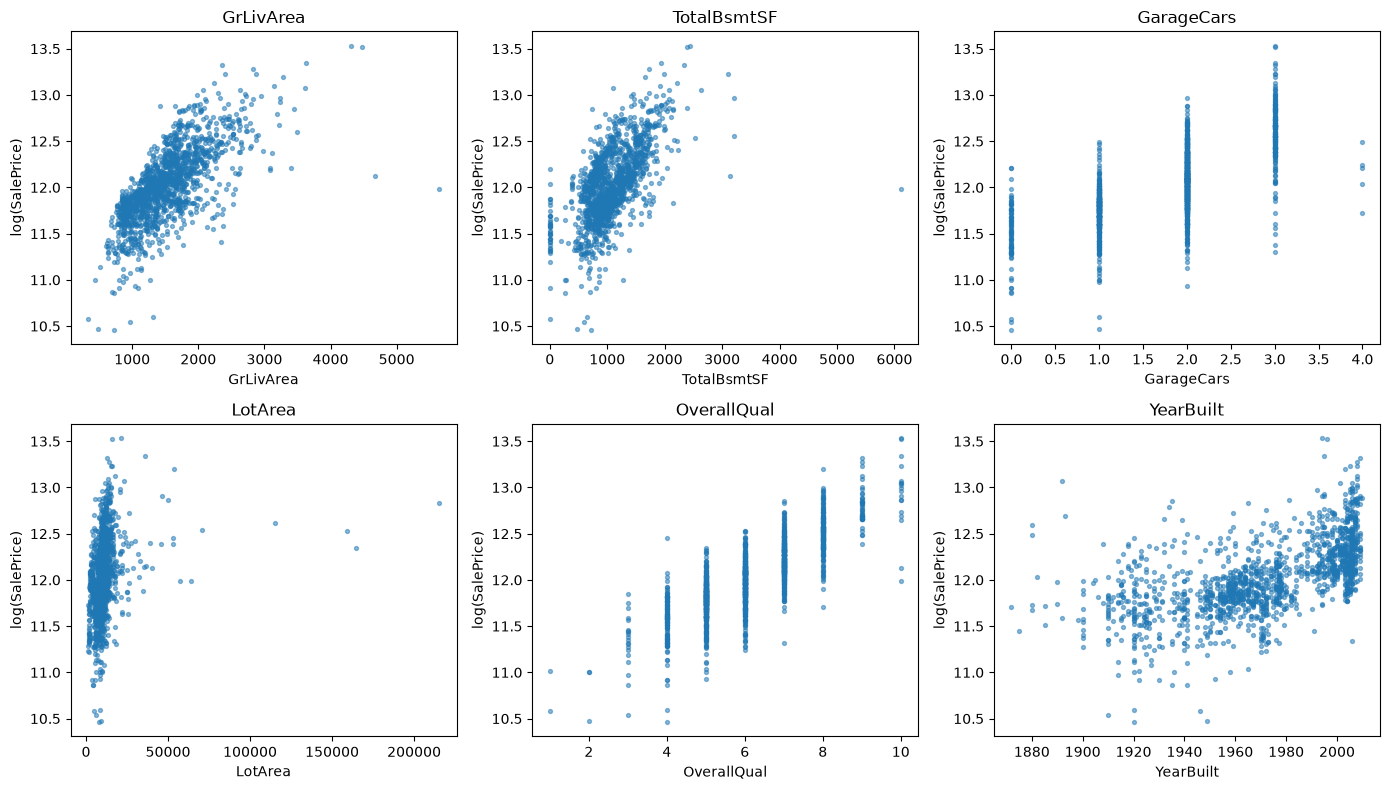

In [122]:
features = ["GrLivArea", "TotalBsmtSF", "GarageCars", "LotArea", "OverallQual", "YearBuilt"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, features):
    ax.scatter(train[col], train["LogPrice"], s=8, alpha=0.5)
    ax.set(title=col, xlabel=col, ylabel="log(SalePrice)")
plt.tight_layout()
plt.show()

In [125]:
train[(train["GrLivArea"] > 4500)][["Id", "GrLivArea", "TotalBsmtSF", "LotArea", "SaleCondition", "OverallQual", "SalePrice"]]

,Id,GrLivArea,TotalBsmtSF,LotArea,SaleCondition,OverallQual,SalePrice
523,524,4676,3138,40094,Partial,10,184750
1298,1299,5642,6110,63887,Partial,10,160000


id для удаления: 524 и 1299, это выбросы, потому что высокая общая оценка и площадь, но при этом невысокая цена.

Логарифмируем LotArea, тут явнйы скос вправо, остальное в целом можно оставить и так, довольно неплохая зависимость с таргетом и так. Также это больше поомщь для линейных моделй, деревьям это не поможет.

In [143]:
rows = []
for col in cat_cols:
    stats = train.groupby(col)["LogPrice"].agg(["median", "count"])
    stats = stats[stats["count"] >= 10] 
    rows.append({
        "feature": col,
        "n_categories": train[col].nunique(),
        "spread": stats["median"].max() - stats["median"].min(),
    })

cat_summary = pd.DataFrame(rows).sort_values("spread", ascending=False)
cat_summary.head(15)

,feature,n_categories,spread
18,ExterQual,4,1.489033
8,Neighborhood,25,1.275236
21,BsmtQual,4,1.043553
0,MSZoning,5,1.017722
30,KitchenQual,4,1.013173
32,FireplaceQu,5,0.871355
15,Exterior1st,15,0.783988
16,Exterior2nd,16,0.765883
20,Foundation,6,0.677432
42,SaleCondition,6,0.632090


In [145]:
rare = []
for col in cat_cols:
    counts = train[col].value_counts()
    small = counts[counts < 10]
    if len(small) > 0:
        rare.append({
            "feature": col,
            "n_categories": len(counts),
            "n_rare": len(small),
            "rare_rows": small.sum(),
            "rare_values": dict(small),
        })

pd.DataFrame(rare).sort_values("rare_rows", ascending=False)

,feature,n_categories,n_rare,rare_rows,rare_values
23,SaleType,9,6,28,"{'ConLD': 9, 'ConLI': 5, 'ConLw': 5, 'CWD': 4,..."
20,GarageCond,5,3,18,"{'Gd': 9, 'Po': 7, 'Ex': 2}"
10,Exterior2nd,16,5,17,"{'Brk Cmn': 7, 'Stone': 5, 'AsphShn': 3, 'Othe..."
4,Condition1,9,3,15,"{'PosA': 8, 'RRNn': 5, 'RRNe': 2}"
5,Condition2,8,7,15,"{'Feedr': 6, 'Artery': 2, 'RRNn': 2, 'PosN': 2..."
8,RoofMatl,8,6,15,"{'WdShngl': 6, 'WdShake': 5, 'Metal': 1, 'Memb..."
18,GarageType,6,2,15,"{'CarPort': 9, '2Types': 6}"
14,Heating,6,4,14,"{'Grav': 7, 'Wall': 4, 'OthW': 2, 'Floor': 1}"
3,Neighborhood,25,2,11,"{'NPkVill': 9, 'Blueste': 2}"
12,Foundation,6,2,9,"{'Stone': 6, 'Wood': 3}"


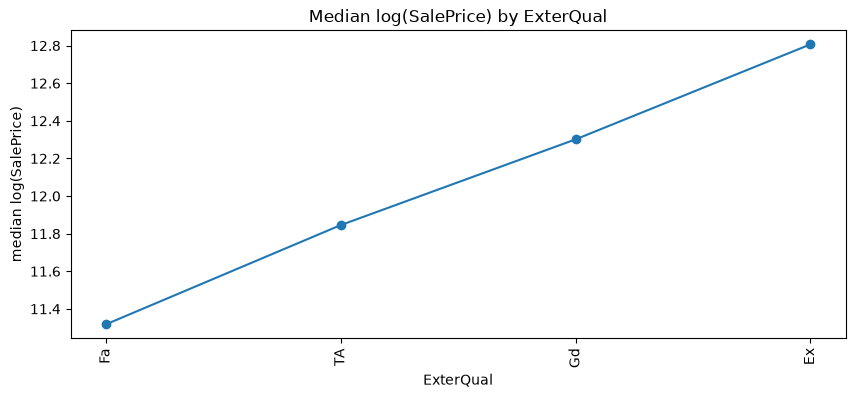

,median,count
ExterQual,,
Fa,11.317514,14
TA,11.845461,906
Gd,12.301383,488
Ex,12.806547,52


In [131]:
col = "ExterQual"
stats = train.groupby(col)["LogPrice"].agg(["median", "count"]).sort_values("median")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats.index, stats["median"], marker="o")
ax.set(title=f"Median log(SalePrice) by {col}", xlabel=col, ylabel="median log(SalePrice)")
plt.xticks(rotation=90)
plt.show()

stats

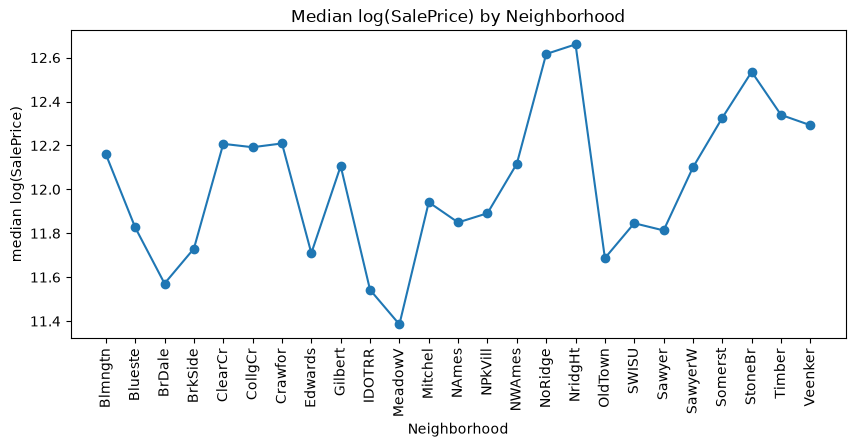

,median,count
Neighborhood,,
Blmngtn,12.160029,17
Blueste,11.826536,2
BrDale,11.571194,16
BrkSide,11.730217,58
ClearCr,12.207321,28
CollgCr,12.191967,150
Crawfor,12.209188,51
Edwards,11.709622,100
Gilbert,12.106252,79


In [141]:
col = "Neighborhood"
stats = train.groupby(col)["LogPrice"].agg(["median", "count"])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats.index, stats["median"], marker="o")
ax.set(title=f"Median log(SalePrice) by {col}", xlabel=col, ylabel="median log(SalePrice)")
plt.xticks(rotation=90)
plt.show()

stats

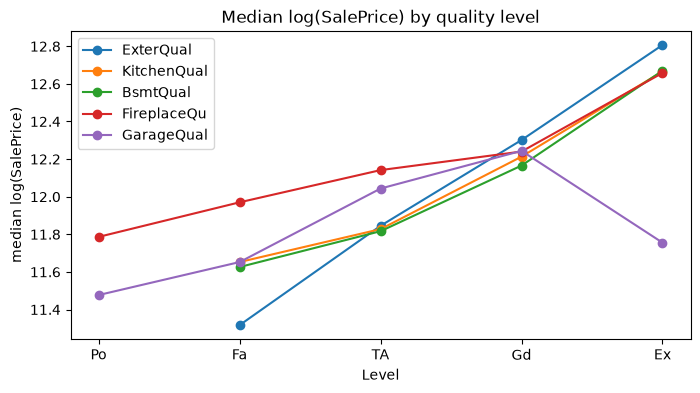

In [142]:
order = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
qual_cols = ["ExterQual", "KitchenQual", "BsmtQual", "FireplaceQu", "GarageQual"]

fig, ax = plt.subplots(figsize=(8, 4))
for col in qual_cols:
    med = train.groupby(col)["LogPrice"].median().reindex(order)
    ax.plot(order, med.values, marker="o", label=col)
ax.set(title="Median log(SalePrice) by quality level", xlabel="Level", ylabel="median log(SalePrice)")
ax.legend()
plt.show()

In [146]:
train["GarageQual"].value_counts()


GarageQual
TA    1311
Fa      48
Gd      14
Ex       3
Po       3
Name: count, dtype: int64

По категориальным: сильнее всего на цену влияют ExterQual, Neighborhood, BsmtQual, MSZoning и KitchenQual. У шкал качества (Po < Fa < TA < Gd < Ex) цена растет лесенкой, поэтому их будем кодировать числами по порядку, а не OHE. GarageQual скачет, но это из-за маленьких групп (Po и Ex всего по 3 дома), так что порядок тоже оставляем.

У Neighborhood естественного порядка нет, на графике он выглядел упорядоченным только из-за сортировки по медиане, поэтому для него OHE или нативные категории для бустинга.

Редкие категории (меньше 10 домов) в первой версии не трогаю, в Other не объединяю.

In [147]:
cols = list(num_cols) + list(cat_cols)
top_share = pd.Series(
    {col: train[col].value_counts(normalize=True, dropna=False).iloc[0] for col in cols}
).sort_values(ascending=False)

top_share[top_share > 0.95]

Utilities       0.999315
Street          0.995890
PoolArea        0.995205
PoolQC          0.995205
Condition2      0.989726
3SsnPorch       0.983562
LowQualFinSF    0.982192
RoofMatl        0.982192
Heating         0.978082
MiscVal         0.964384
MiscFeature     0.963014
KitchenAbvGr    0.953425
dtype: float64

Почти полностью константные признаки, следовательно кандидаты на удаление

## Итог EDA

**Таргет и валидация**
- учим на log(SalePrice), предсказание переводим обратно через exp
- метрика RMSE на логах, как на каггле, смотрим на KFold из 5 фолдов

**Удаляем строки**
- Id 524 и 1299: огромная площадь и качество 10, но дешево, плюс SaleCondition = Partial (продан недостроенным).

**Удаляем признаки**
- Id
- дубли с корреляцией > 0.8: GarageArea, GarageYrBlt, TotRmsAbvGrd, 1stFlrSF
- почти константные (> 99%): Utilities, Street, PoolArea, PoolQC
- остальные из 95–99% пока оставляю, бустинг сам с ними разберется

**Пропуски**
- заполняем по плану выше, только GarageYrBlt, GarageArea, PoolQC и Utilities там уже не нужны, их удаляем
- медиану и моду считаем только на трейн фолде, чтобы не было утечки

**Кодирование**
- шкалы качества (ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond) -> числа по порядку: None=0, Po=1, Fa=2, TA=3, Gd=4, Ex=5
- MSSubClass по сути категория, хоть и записан числом, переводим в строку, чтобы он стал категориальным и закодировался
- остальные категориальные: OHE для линейных моделей, нативные категории для бустинга

**Только для линейных моделей**
- log1p(LotArea)
- scaling числовых признаков

**Будущие эксперименты**
- объединение редких категорий в Other
- target encoding для Neighborhood (только внутри фолда)
- log1p для других скошенных площадей

## Анализ ошибок

Смотрим ошибки лучшей модели по CV (Lasso) на ее OOF. Остаток = y - предсказание: больше 0 модель недооценила дом, меньше 0 переоценила.

5% худших домов дают 49% всей квадратичной ошибки


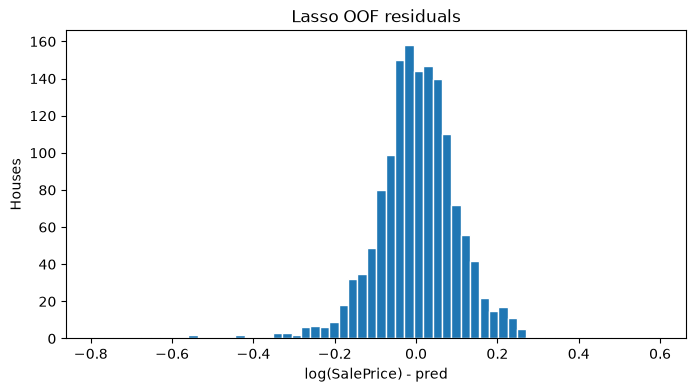

In [182]:
data = train[~train["Id"].isin([524, 1299])].reset_index(drop=True)
data["pred"] = np.load("../experiments/lasso_full_prep/oof.npy")
data["resid"] = data["LogPrice"] - data["pred"]
data["abs_resid"] = data["resid"].abs()

squared = (data["resid"] ** 2).sort_values(ascending=False)
top_share = squared.head(int(len(data) * 0.05)).sum() / squared.sum()
print(f"5% худших домов дают {top_share:.0%} всей квадратичной ошибки")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(data["resid"], bins=60, edgecolor="white")
ax.set(title="Lasso OOF residuals", xlabel="log(SalePrice) - pred", ylabel="Houses")
plt.show()

5% худших домов дают почти половину всей ошибки, значит она сосредоточена в небольшой группе домов и смотреть надо именно на них.

In [183]:
data["price_group"] = pd.qcut(data["pred"], 5, labels=["1 cheapest", "2", "3", "4", "5 most expensive"])
data.groupby("price_group")["resid"].agg(["mean", "std", "count"])

,mean,std,count
price_group,,,
1 cheapest,0.008209,0.156175,292
2,0.006807,0.090925,291
3,-0.000419,0.081289,292
4,-0.015919,0.102694,291
5 most expensive,0.004366,0.109350,292


По всем ценовым группам средний остаток около 0, то есть смещения по цене нет, но у самых дешевых домов разброс ошибки почти в 2 раза больше, чем в середине.

In [184]:
data.sort_values("abs_resid", ascending=False)[
    ["Id", "OverallQual", "GrLivArea", "Neighborhood", "SaleCondition", "SalePrice", "resid"]
].head(10)

,Id,OverallQual,GrLivArea,Neighborhood,SaleCondition,SalePrice,resid
631,633,7,1411,NWAmes,Family,82500,-0.791160
30,31,4,1317,IDOTRR,Normal,40000,-0.739247
1322,1325,8,1795,Somerst,Partial,147000,-0.652597
462,463,5,864,Sawyer,Normal,62383,-0.650370
967,969,3,968,OldTown,Abnorml,37900,-0.615498
88,89,3,1526,IDOTRR,Abnorml,85000,0.594908
587,589,5,1473,ClearCr,Partial,143000,-0.571763
495,496,4,720,IDOTRR,Abnorml,34900,-0.557781
410,411,5,1276,Edwards,Abnorml,60000,-0.553245
969,971,4,1192,NAmes,Abnorml,135000,0.468939


Почти все худшие дома дешевые и модель их переоценила, а у большинства SaleCondition не Normal, та же история, что с выбросами 524 и 1299 из EDA.

In [185]:
worst = data.sort_values("abs_resid", ascending=False).head(20)

pd.DataFrame({
    "worst_20": worst["SaleCondition"].value_counts(normalize=True),
    "all": data["SaleCondition"].value_counts(normalize=True),
}).round(3)

,worst_20,all
SaleCondition,,
Abnorml,0.50,0.069
AdjLand,NaN,0.003
Alloca,0.05,0.008
Family,0.05,0.014
Normal,0.25,0.822
Partial,0.15,0.084


Abnorml среди 20 худших домов 50% при 7% в целом, то есть проблемные продажи попадают в худшие ошибки в 7 раз чаще.

In [186]:
data.groupby("SaleCondition")["resid"].agg(["mean", "std", "count"])

,mean,std,count
SaleCondition,,,
Abnorml,-0.009155,0.197324,101
AdjLand,0.058863,0.089633,4
Alloca,-0.010467,0.189374,12
Family,-0.028780,0.230911,20
Normal,0.001344,0.093186,1198
Partial,0.005518,0.137390,123


При этом средний остаток у Abnorml и Family около 0, а разброс в 2 раза больше, чем у Normal, значит это не систематическая ошибка, а шум: цена при проблемной продаже зависит от того, чего нет в данных, и признаком это не исправить.

In [187]:
data[num_cols].corrwith(data["resid"]).abs().sort_values(ascending=False).head(10)

PoolArea        0.031403
GarageArea      0.024734
TotRmsAbvGrd    0.019326
GarageYrBlt     0.015767
1stFlrSF        0.013890
3SsnPorch       0.013753
BsmtFinSF1      0.009383
GarageCars      0.009007
TotalBsmtSF     0.008543
Fireplaces      0.008120
dtype: float64

С числовыми признаками остаток почти не коррелирует (максимум 0.03), значит линейную информацию из них Lasso уже взяла, а удаленные в EDA дубли (GarageArea, TotRmsAbvGrd, GarageYrBlt, 1stFlrSF) с остатком тоже почти не связаны, удаление ничего не стоило.

In [188]:
rows = []
for col in cat_cols:
    stats = data.groupby(col)["resid"].agg(["mean", "count"])
    stats = stats[stats["count"] >= 10]
    rows.append({"feature": col, "spread": stats["mean"].max() - stats["mean"].min()})

pd.DataFrame(rows).sort_values("spread", ascending=False).head(10)

,feature,spread
0,MSZoning,0.138097
9,Condition1,0.097272
8,Neighborhood,0.094391
31,Functional,0.069046
25,BsmtFinType2,0.060707
17,MasVnrType,0.059241
35,GarageQual,0.048845
14,RoofMatl,0.046874
13,RoofStyle,0.046173
36,GarageCond,0.046087


Сильнее всего средний остаток отличается между группами MSZoning, Condition1 и Neighborhood.

In [189]:
for col in ["MSZoning", "Condition1", "Neighborhood"]:
    stats = data.groupby(col)["resid"].agg(["mean", "count"])
    print(stats[stats["count"] >= 10].sort_values("mean").head(3), "\n")

              mean  count
MSZoning                 
C (all)  -0.109148     10
RM       -0.002811    218
RL        0.001206   1149 

                mean  count
Condition1                 
RRAe       -0.068594     11
Artery     -0.013191     48
Norm        0.001154   1260 

                  mean  count
Neighborhood                 
MeadowV      -0.051842     17
IDOTRR       -0.014791     37
Mitchel      -0.014508     49 



Этот разброс дают маленькие группы (C (all), RRAe, MeadowV, по 10–17 домов), которые модель переоценивает: признаки для них в OHE есть, но регуляризация Lasso прижимает коэффициенты редких колонок к нулю, это должен закрыть бустинг в ансамбле.

## Новые признаки

In [190]:
skew = data[num_cols].skew().sort_values(ascending=False)
skew[skew > 1]

MiscVal          24.460085
PoolArea         15.948945
LotArea          12.573925
3SsnPorch        10.297106
LowQualFinSF      9.004955
KitchenAbvGr      4.484883
BsmtFinSF2        4.251925
ScreenPorch       4.118929
BsmtHalfBath      4.100114
EnclosedPorch     3.087164
MasVnrArea        2.687784
OpenPorchSF       2.339829
WoodDeckSF        1.545805
LotFrontage       1.543043
MSSubClass        1.407011
GrLivArea         1.010992
dtype: float64

Сильно скошены в основном площади и признаки, где почти все нули (MiscVal, PoolArea, веранды), но скос сам по себе не значит, что логарифм поможет, поэтому проверяем напрямую по корреляции с таргетом.

In [191]:
areas = ["LotArea", "GrLivArea", "TotalBsmtSF", "MasVnrArea", "LotFrontage", "BsmtFinSF1", "OpenPorchSF", "WoodDeckSF"]

pd.DataFrame({
    "raw": data[areas].corrwith(data["LogPrice"]),
    "log": np.log1p(data[areas]).corrwith(data["LogPrice"]),
    "zeros": data[areas].eq(0).mean(),
}).round(3)

,raw,log,zeros
LotArea,0.261,0.403,0.000
GrLivArea,0.725,0.737,0.000
TotalBsmtSF,0.648,0.373,0.025
MasVnrArea,0.435,0.419,0.591
LotFrontage,0.373,0.368,0.000
BsmtFinSF1,0.392,0.208,0.320
OpenPorchSF,0.325,0.461,0.450
WoodDeckSF,0.334,0.343,0.522


Логарифм заметно поднимает корреляцию только у LotArea (уже логарифмируем) и OpenPorchSF, у GrLivArea чуть-чуть, а TotalBsmtSF и BsmtFinSF1 из-за нулей становятся хуже, значит в log_columns добавляем GrLivArea и OpenPorchSF.

In [192]:
data["TotalSF"] = data["TotalBsmtSF"] + data["GrLivArea"]
data["TotalBath"] = data["FullBath"] + 0.5 * data["HalfBath"] + data["BsmtFullBath"] + 0.5 * data["BsmtHalfBath"]
data["HouseAge"] = data["YrSold"] - data["YearBuilt"]

new = ["TotalSF", "TotalBath", "HouseAge"]
pd.DataFrame({
    "corr_target": data[new].corrwith(data["LogPrice"]),
    "corr_resid": data[new].corrwith(data["resid"]),
})

,corr_target,corr_resid
TotalSF,0.820738,0.008600
TotalBath,0.676678,0.002463
HouseAge,-0.587767,-0.005433


Новые суммы сильно коррелируют с таргетом, но с остатком Lasso около 0, потому что это линейные комбинации признаков, которые у нее уже есть, поэтому проверяем их только на бустинге, деревьям складывать признаки сложно.

In [193]:
dummies = pd.get_dummies(data[cat_cols])
rare = dummies.sum() < 10

print(f"OHE columns: {dummies.shape[1]}, rare: {rare.sum()}, left: {dummies.shape[1] - rare.sum()}")

OHE columns: 251, rare: 68, left: 183


После OHE 251 колонка, из них 68 встречаются меньше чем у 10 домов, для MLP и Lasso это шум, поэтому объединяем их в одну, а маленькие группы с ошибкой (от 10 домов) при этом остаются.

## Ансамбль

In [194]:
models = ["lasso", "cat_boost", "xgboost", "lightgbm", "mlp"]
oof = pd.DataFrame({model: np.load(f"../experiments/{model}_full_prep/oof.npy") for model in models})
resid = oof.rsub(data["LogPrice"], axis=0)

resid.corr().round(3)

,lasso,cat_boost,xgboost,lightgbm,mlp
lasso,1.000,0.869,0.866,0.836,0.884
cat_boost,0.869,1.000,0.952,0.921,0.859
xgboost,0.866,0.952,1.000,0.939,0.848
lightgbm,0.836,0.921,0.939,1.000,0.826
mlp,0.884,0.859,0.848,0.826,1.000


Ошибки бустингов между собой коррелируют на 0.92–0.95, а Lasso и MLP с бустингами на 0.83–0.87, то есть они ошибаются по-разному, и в ансамбль берем Lasso, MLP и один бустинг, а не три бустинга.

## Итог

Большая часть ошибки это шум в проблемных продажах, признаками его не исправить, а линейную информацию из числовых признаков Lasso уже взяла, поэтому от новых признаков большого прироста не жду, основной прирост должен дать ансамбль.

Эксперименты, по одному изменению за раз:
1. log_columns: добавить GrLivArea и OpenPorchSF, проверяем на Lasso и MLP
2. OHE с min_frequency=10, проверяем на Lasso и MLP
3. TotalSF, TotalBath, HouseAge, проверяем на CatBoost и XGBoost
4. ансамбль из Lasso, MLP и лучшего бустинга: блендинг и стекинг по OOF

In [197]:
log = pd.read_csv("../experiments/log.csv")

log

,timestamp,experiment_name,git_hash,git_dirty,model,cv_mean,cv_sd,public
0,2026-11-14T16:15:26,baseline_v1,124b0da,False,linear_regression,0.128793,0.008759,0.14456
1,2026-11-14T19:53:35,linreg_full_prep,a858e44,False,linear_regression,0.128712,0.011135,0.14345
2,2026-11-14T19:59:30,ridge_full_prep,ebefacd,False,ridge,0.117825,0.006978,0.13697
3,2026-11-14T20:06:47,lasso_full_prep,9e3d477,False,lasso,0.111161,0.005890,0.13288
4,2026-11-14T20:08:56,elastic_net_full_prep,a6ded52,False,elastic_net,0.112454,0.005607,0.13325
5,2026-11-14T20:14:08,knn_full_prep,07ca071,False,knn,0.170918,0.009942,0.17524
6,2026-11-14T20:15:56,decision_tree_full_prep,07ca071,True,decision_tree,0.195273,0.010173,0.16992
7,2026-11-14T20:17:50,random_forest_full_prep,07ca071,True,random_forest,0.130747,0.007224,0.14141
8,2026-11-14T20:20:52,cat_boost_full_prep,fad9179,False,cat_boost,0.113301,0.006671,0.12477
9,2026-11-14T20:27:55,lightgbm_full_prep,fad9179,False,lightgbm,0.117203,0.007705,0.12535
